<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_20_Perplexity_over_Sequences_texts_and_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import requests
from datasets import load_dataset

from tqdm import tqdm

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Perplexity over Time

## Task_1:
- Import the GPT-2 model and its tokenizer. Switch the model into
eval mode and push it to the GPU. You’ll import several models
later in the project, and use the variable name model in a function
in Part 2, so I recommend naming the model here gpt2.
Import the text for the book Frankenstein’s Monster from guten
berg.org. You can find and copy code from Chapter 2, or check the
online solution for the importing code.
Define a variable for the sequence length to use in averaging
the loss as the maximum sequence length of the model (hint: check
gpt2.config), and calculate the number of non-overlapping text
segments that can be extracted from the text tokens.

In [2]:
gpt2tokenizer=AutoTokenizer.from_pretrained('gpt2')
gpt2=AutoModelForCausalLM.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [3]:
gpt2.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpt2.to(device);


In [5]:
device

device(type='cuda')

In [14]:
baseurl = 'https://www.gutenberg.org/cache/epub/84/pg84.txt'
text = requests.get(baseurl).text
print(text[:1000])


The Project Gutenberg eBook of Frankenstein; or, The modern Prometheus
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Frankenstein; or, The modern Prometheus

Author: Mary Wollstonecraft Shelley


        
Release date: October 1, 1993 [eBook #84]
                Most recently updated: February 10, 2026

Language: English

Other information and formats: www.gutenberg.org/ebooks/84

Credits: Judith Boss, Christy Phillips, Lynn Hanninen and David Meltzer. HTML version by Al Haines.
        Further corrections by Menno de Leeuw.


*** START OF THE PROJECT GUTEN


In [7]:
tokens =gpt2tokenizer.encode(text,return_tensors='pt')
num_tokens =tokens.shape[-1]
print(f'Number of tokens: {num_tokens:,}')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (114211 > 1024). Running this sequence through the model will result in indexing errors


Number of tokens: 114,211


In [8]:
gpt2.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "use_cache": true,
  "vocab_size": 50257
}

In [9]:
len(tokens[0]),tokens.shape[-1]

(114211, 114211)

In [10]:
# max sequence length
seq_len =gpt2.config.n_positions
print(f'Sequence length: {seq_len}')

# how many samples fit into the data
nSegments =len(tokens[0])//seq_len
print(f'Number of non-overlapping segments: {nSegments:,}')

Sequence length: 1024
Number of non-overlapping segments: 111


## Task_2
- Create a for-loop over segments, in which the following steps are
implemented.
1. Define start and endpoint segment indices into the token se
quence. Each segment is 1024 tokens long, and non-overlapping
with the previous segment. (Hint: The start index can be de
fined as a multiple of the looping index variable.)
2. Extract the tokens from those indices and move them to the
GPU.
3. Run a forward pass and get the outputs and the loss. You
can implement that on your own as you learned in Project 19,
although it’s easiest to use the labels= optional input argument
when calling the model.
4. Accumulate the segment-averaged loss. This is the summation
term inside the natural exponential in Equation 4.13. You only
need to sum here; do not apply the natural exponential.
5. Implement the full Equation 4.13 on the loss from this segment,
and store as an element in an array to be used for plotting.
6. After the for-loop, finalize calculating the total perplexity from
Step 4 by implementing the rest of Equation 4.13.
Visualize the per-segment perplexity values, the perplexity of the ac
cumulated losses (from Step 6), and the average of the per-segment
perplexities (from Step 5), as in Figure 4.16

In [11]:
tokens[0][0:1024].unsqueeze(0).shape

torch.Size([1, 1024])

In [12]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [15]:
perplexities = np.zeros(nSegments)

sum_losses = 0.

for segi in tqdm(range(nSegments)):
  # 1) start and end indices
  start = segi * seq_len
  end = start + seq_len

  # 2) extract the data and push to the GPU
  X = tokens[0][start:end].unsqueeze(0).to(device)

  # 3) forward pass
  with torch.no_grad():
    outputs = gpt2(X,labels=X)

  # 4) accumulated loss for later perplexity calculations
  sum_losses += outputs.loss.item()

  # 5) per-segment perplexity
  perplexities[segi] = torch.exp(outputs.loss).item()

# 6) calculate perplexity
ave_perplexity = torch.exp( torch.tensor(sum_losses) / nSegments )

100%|██████████| 111/111 [00:09<00:00, 11.91it/s]


In [21]:
sum_losses

579.9818730354309

In [19]:
perplexities,ave_perplexity

(array([211.64329529, 209.49530029, 234.05439758, 214.88056946,
        290.22116089, 156.1897583 , 221.67530823, 216.97801208,
        191.32954407, 194.40956116, 236.96461487, 215.13114929,
        204.54167175, 241.58784485, 193.49978638, 201.063797  ,
        182.29130554, 205.82383728, 180.31658936, 189.14431763,
        220.18998718, 190.58045959, 212.79710388, 165.84220886,
        210.87257385, 187.61380005, 217.98382568, 182.10800171,
        200.36999512, 236.85783386, 189.35269165, 176.80458069,
        165.87240601, 209.93479919, 151.01855469, 175.32287598,
        146.03401184, 178.71739197, 269.70083618, 207.6125946 ,
        258.64111328, 260.07269287, 224.18450928, 179.44219971,
        176.99588013, 154.48399353, 157.16081238, 145.53689575,
        157.5093689 , 162.78862   , 185.55953979, 229.99276733,
        164.90925598, 211.05323792, 204.28121948, 178.17248535,
        161.78286743, 217.25361633, 190.96151733, 223.0038147 ,
        125.74849701, 142.76150513, 171.

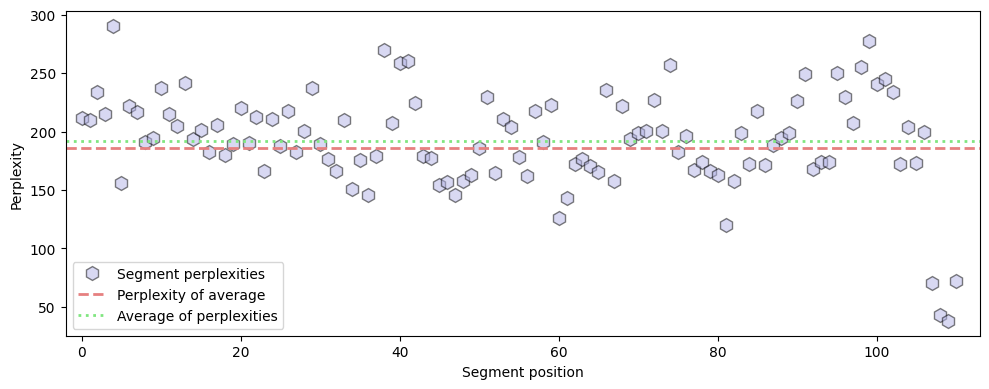

In [22]:
plt.figure(figsize=(10,4))

plt.plot(perplexities,'kh',markersize=10,markerfacecolor=[.7,.7,.9,.5],label='Segment perplexities')
plt.axhline(ave_perplexity,linestyle='--',color=[.9,.5,.5],linewidth=2,label='Perplexity of average')
plt.axhline(perplexities.mean(),linestyle=':',color=[.5,.9,.5],linewidth=2,label='Average of perplexities')

plt.legend()
plt.gca().set(xlabel='Segment position',ylabel='Perplexity',xlim=[-2,nSegments+2])

plt.tight_layout()
plt.show()

# Part_2: A Perplexity Function

## Task_1:
- Create a Python function that takes three inputs: a token sequence,
a model, and a sequence length. Inside the function, calculate
perplexity using the code you developed previously (use the accumu
lated loss described in Steps 4&6). The function should return the
perplexity score.Check the variable names carefully: the function needs to use
the tokens, model, and sequence length provided as inputs — not
global variables defined in the previous Part.

In [23]:

def calc_perplex(tokens,model=gpt2,seq_len=gpt2.config.n_positions):

  # number of segments in the total token sequence
  nSegments =len(tokens[0])//seq_len

  # initialize losses
  sum_losses = 0.

  for i in range(nSegments):

    # find start and end indices
    start =i*seq_len
    end =start + seq_len

    # get the token sequence (with batch dimension)
    X = tokens[0][start:end].unsqueeze(0).to(device)

    # forward pass
    with torch.no_grad():
      outputs =model(X,labels=X)

    # calculate and store this batch's loss
    sum_losses +=outputs.loss.item()

  # after segments loop, perplexity = exp(average per-token losses over this segment)
  perplexity = torch.exp( torch.tensor(sum_losses) / nSegments )

  return perplexity


In [24]:

calc_perplex(tokens)

tensor(185.8727)

In [25]:

ave_perplexity

tensor(185.8727)

# Part 3: Impact of sequence length

## Task_1:
- Call the perplexity function six times using the same tokens and the
same model, but sequence lengths of 2N for N = [5,6,7,8,9,10].
Report the results as text output, and visualize the results in a bar
plot as in Figure 4.17.

In [29]:
N=[5,6,7,8,9,10]
for i in N:
  print(f"Sequence Length {2**i} has Perplexity {calc_perplex(tokens,seq_len=2**i)}")


Sequence Length 32 has Perplexity 807.1384887695312
Sequence Length 64 has Perplexity 454.216796875
Sequence Length 128 has Perplexity 309.12554931640625
Sequence Length 256 has Perplexity 242.01654052734375
Sequence Length 512 has Perplexity 205.77330017089844
Sequence Length 1024 has Perplexity 185.8726806640625


In [30]:

seq_lengths = 2**np.arange(5,11)

perp_by_len = np.zeros(len(seq_lengths))

for i in tqdm(range(len(seq_lengths))):
  perp_by_len[i] = calc_perplex(tokens,seq_len=seq_lengths[i])

print('\n')
for i in range(len(seq_lengths)):
  print(f'Sequence length {seq_lengths[i]:4} has perplexity {perp_by_len[i]:6.2f}')

100%|██████████| 6/6 [01:45<00:00, 17.61s/it]



Sequence length   32 has perplexity 807.14
Sequence length   64 has perplexity 454.22
Sequence length  128 has perplexity 309.13
Sequence length  256 has perplexity 242.02
Sequence length  512 has perplexity 205.77
Sequence length 1024 has perplexity 185.87


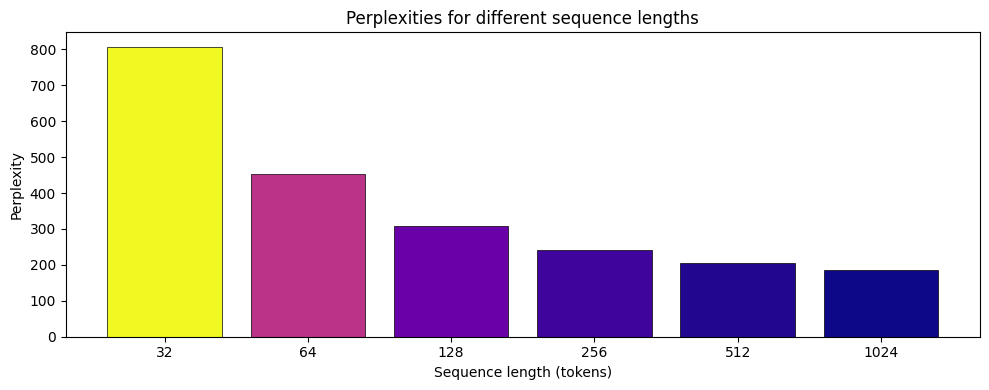

In [31]:
plt.figure(figsize=(10,4))

perpl_scaled = (perp_by_len - perp_by_len.min()) / (perp_by_len.max() - perp_by_len.min())

plt.bar(range(len(seq_lengths)),perp_by_len,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(perpl_scaled))
plt.gca().set(xticks=range(len(perp_by_len)),xticklabels=seq_lengths,xlabel='Sequence length (tokens)',
              ylabel='Perplexity',title='Perplexities for different sequence lengths')

plt.tight_layout()
plt.show()

# Part 4: Perplexities in different texts

## Task_1:
- Find and copy code from Chapter 2 to import the 10 English novels
from gutenberg.org. In a for-loop over the texts, import and tokenize
the text, and calculate perplexity for each text. Use a sequence
length of 1024.
Books have different lengths, which presents a confound for a
direct comparison. Therefore, calculate the perplexity using only the
first 50,000 tokens from each book.
Print the results and show in a bar plot as in Figure 4.18

In [36]:
baseurl='https://www.gutenberg.org/cache/epub/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'    ],
    ['64317', 'GreatGatsby'     ],
    ['11',    'AliceWonderland' ],
    ['1513',  'RomeoJuliet'     ],
    ['76',    'HuckFinn'        ],
    ['219',   'HeartDarkness'   ],
    ['2591',  'GrimmsTales'     ],
    ['2148',  'EdgarAllenPoe'   ],
    ['36',    'WarOfTheWorlds'  ],
    ['829',   'GulliversTravels']
]

In [37]:

ppls = np.zeros(len(bookurls))

for i,(code,title) in enumerate(bookurls):

  # get the text tokens
  fullurl = baseurl + code + '/pg' + code + '.txt'
  text = requests.get(fullurl).text
  tokens = gpt2tokenizer.encode(text,return_tensors='pt')

  # just the first 50k tokens for speed and direct comparison
  tokens = tokens[:50000]

  # calculate perplexity
  ppls[i] = calc_perplex(tokens)

  print(f'{title:>16} has perplexity {ppls[i]:6.2f}')

    Frankenstein has perplexity 185.87
     GreatGatsby has perplexity 140.23
 AliceWonderland has perplexity  92.29
     RomeoJuliet has perplexity 240.13
        HuckFinn has perplexity 146.50
   HeartDarkness has perplexity 161.25
     GrimmsTales has perplexity  91.95
   EdgarAllenPoe has perplexity  71.41
  WarOfTheWorlds has perplexity 196.55
GulliversTravels has perplexity 165.96


In [39]:
ppls

array([185.87268066, 140.22680664,  92.28946686, 240.12684631,
       146.49508667, 161.25382996,  91.94939423,  71.41122437,
       196.55024719, 165.95960999])

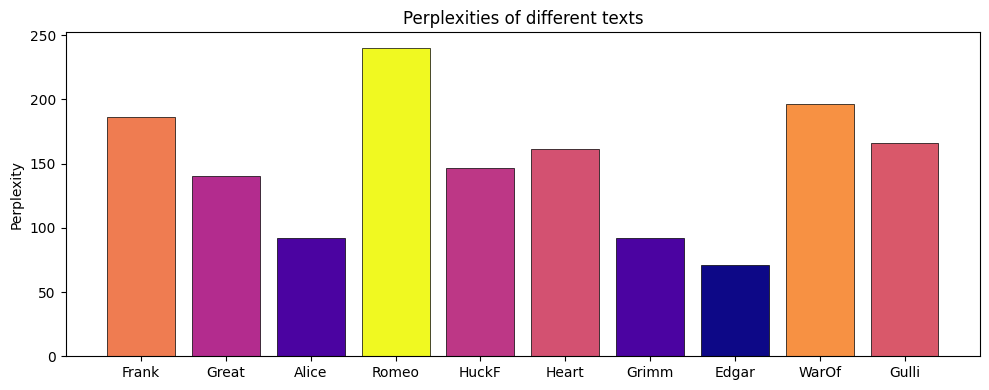

In [38]:
plt.figure(figsize=(10,4))

# min-max scaling for coloring the bars
ppls_scaled = (ppls - ppls.min()) / (ppls.max() - ppls.min())

# and draw the bars
plt.bar(range(len(ppls)),ppls,edgecolor='k',linewidth=.5,
        color=plt.cm.plasma(ppls_scaled))
plt.gca().set(xticks=range(len(ppls)),xticklabels=[bookurls[i][1][:5] for i in range(len(bookurls))],
              ylabel='Perplexity',title='Perplexities of different texts')

plt.tight_layout()
plt.show()